# Task 2 · Notebook 02 — Feature Engineering & Modelling

**Input.** `data/processed/bookings_clean.csv` (49,281 bookings, duplicates removed in Notebook 01).

**Approach**
1. Prepare features (convert text to numbers, split routes into airports).
2. Split the data into training, validation and test sets **before** any model sees it.
3. Compare several models fairly using cross-validation on the training set.
4. Choose a decision threshold on the validation set.
5. Measure final performance **once** on the untouched test set (Notebook 03).

**Why the order matters.** The original version of this project fitted encodings on the full dataset and tuned its threshold on the test set. Both let information from the test data leak into the model, making results look better than they would be on genuinely new customers.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/processed/bookings_clean.csv")

# Day name -> number (Mon = 1 ... Sun = 7)
df["flight_day"] = df["flight_day"].map({"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7})

# A route like "AKLDEL" is two 3-letter airport codes: origin (AKL) + destination (DEL)
df["origin"] = df["route"].str[:3]
df["destination"] = df["route"].str[3:]

print(f"{len(df):,} bookings")
df[["route", "origin", "destination", "flight_day"]].head()

49,281 bookings


,route,origin,destination,flight_day
0,AKLDEL,AKL,DEL,6
1,AKLDEL,AKL,DEL,6
2,AKLDEL,AKL,DEL,3
3,AKLDEL,AKL,DEL,6
4,AKLDEL,AKL,DEL,3


In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["booking_complete", "route"])     # route is replaced by origin + destination
y = df["booking_complete"]

# 60% train / 20% validation / 20% test, keeping the 15% booking rate in each
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} {len(part):>6,} rows   booking rate {part.mean():.1%}")

Train       29,568 rows   booking rate 15.0%
Validation   9,856 rows   booking rate 15.0%
Test         9,857 rows   booking rate 15.0%


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC = ["num_passengers", "purchase_lead", "length_of_stay", "flight_hour", "flight_day",
           "flight_duration", "wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]
CATEGORICAL = ["sales_channel", "trip_type", "booking_origin", "origin", "destination"]

def make_preprocessor(scale_numbers=False):
    return ColumnTransformer([
        ("numbers", StandardScaler() if scale_numbers else "passthrough", NUMERIC),
        ("categories", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                     sparse_output=False), CATEGORICAL),
    ])

# Quick look at what it produces (fitted on TRAINING data only)
prep = make_preprocessor().fit(X_train)
print("Columns after preparation:", prep.transform(X_train).shape[1])

Columns after preparation: 138


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

candidates = {
    'Baseline (always "no")': Pipeline([("prep", make_preprocessor()),
                                        ("model", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("prep", make_preprocessor(scale_numbers=True)),
                                     ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", make_preprocessor()),
                               ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                         class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor()),
                                   ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400,
                                             class_weight="balanced", random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for name, pipe in candidates.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    results.append({"model": name,
                    "ROC AUC": scores["test_roc_auc"].mean(),
                    "ROC AUC spread (±)": scores["test_roc_auc"].std(),
                    "PR AUC": scores["test_average_precision"].mean()})
    print(f"done: {name}")

pd.DataFrame(results).set_index("model").round(3)

done: Baseline (always "no")
done: Logistic Regression
done: Random Forest
done: Gradient Boosting


,ROC AUC,ROC AUC spread (±),PR AUC
model,,,
"Baseline (always ""no"")",0.500,0.000,0.150
Logistic Regression,0.773,0.009,0.344
Random Forest,0.785,0.009,0.372
Gradient Boosting,0.787,0.006,0.372


**Model comparison (5-fold cross-validation on the training set)**

All three models clearly beat the baseline. Random Forest and Gradient Boosting tie on PR AUC (0.372). **Gradient Boosting is selected** because it has
- slightly higher ROC AUC (0.787 vs 0.785),
- the most stable scores across folds (± 0.006).

Logistic Regression is weaker (PR AUC 0.344), suggesting the patterns are not purely straight-line effects. For example, booking rate drops sharply after 6 nights and then rises slightly for very long stays.

**Note.** These cross-validation scores are for class-weighted versions of the models. Cell 8 below drops the class weights for the final model, which ranks customers just as well (validation ROC AUC 0.800 with and without weights).

Scores are modest, as Notebook 01 predicted. No single feature strongly separates bookers, so the model improves targeting rather than identifying bookers with certainty.

In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def gradient_boosting(class_weight):
    return Pipeline([("prep", make_preprocessor()),
                     ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400,
                               class_weight=class_weight, random_state=42))])

weighted   = gradient_boosting("balanced").fit(X_train, y_train)
unweighted = gradient_boosting(None).fit(X_train, y_train)

rows = []
for name, m in [("balanced class weights", weighted), ("no class weights", unweighted)]:
    s = m.predict_proba(X_val)[:, 1]
    rows.append({"version": name,
                 "ROC AUC": roc_auc_score(y_val, s),
                 "PR AUC": average_precision_score(y_val, s),
                 "average predicted chance": s.mean(),
                 "actual booking rate": y_val.mean(),
                 "Brier score (lower = better)": brier_score_loss(y_val, s)})
pd.DataFrame(rows).set_index("version").round(3)

,ROC AUC,PR AUC,average predicted chance,actual booking rate,Brier score (lower = better)
version,,,,,
balanced class weights,0.8,0.388,0.404,0.15,0.183
no class weights,0.8,0.387,0.151,0.15,0.108


**Handling the class imbalance**

Balanced class weights did not improve ranking (ROC AUC 0.800 and PR AUC ≈0.39 for both versions) but inflated the scores. The weighted model predicted an average 40% chance of booking against a true rate of 15%. Without weights, the average prediction (15.1%) matches reality and the Brier score improves from 0.183 to 0.108.

**Decision.** Use Gradient Boosting **without** class weights, and handle the imbalance by choosing a lower decision threshold. The model's scores can then be read directly as the chance of booking, which the Streamlit app relies on.

This differs from the original project, which used SMOTE and balanced random forests. Those methods changed where the decision boundary sat, but, as noted in the original README, did not improve the model's underlying ranking ability.

Chosen threshold (max F1 on validation): 0.22
  F1 0.453 | precision 0.357 | recall 0.620 | customers flagged 26.1%


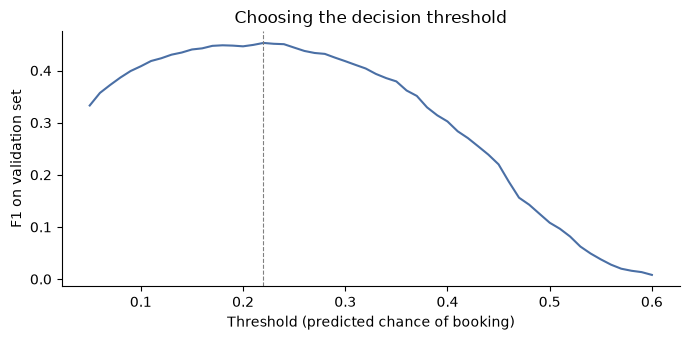

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score

model = unweighted
val_scores = model.predict_proba(X_val)[:, 1]

thresholds = np.round(np.arange(0.05, 0.61, 0.01), 2)
f1_by_threshold = [f1_score(y_val, val_scores >= t) for t in thresholds]
THRESHOLD = float(thresholds[int(np.argmax(f1_by_threshold))])

flagged = val_scores >= THRESHOLD
print(f"Chosen threshold (max F1 on validation): {THRESHOLD}")
print(f"  F1 {max(f1_by_threshold):.3f} | precision {precision_score(y_val, flagged):.3f} | "
      f"recall {recall_score(y_val, flagged):.3f} | customers flagged {flagged.mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thresholds, f1_by_threshold, color="#4a6fa5")
ax.axvline(THRESHOLD, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Threshold (predicted chance of booking)")
ax.set_ylabel("F1 on validation set")
ax.set_title("Choosing the decision threshold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
import json
import joblib
import sklearn

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Final model: same recipe, trained on train + validation (the test set stays untouched)
final_model = gradient_boosting(None).fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
joblib.dump(final_model, MODEL_DIR / "booking_model.joblib")

model_info = {
    "model": "Gradient Boosting (HistGradientBoostingClassifier), no class weights",
    "threshold": THRESHOLD,
    "threshold_rule": "maximum F1 on the validation set",
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "trained_on_rows": int(len(X_train) + len(X_val)),
    "cv_comparison": pd.DataFrame(results).set_index("model").round(3).to_dict(orient="index"),
    "scikit_learn_version": sklearn.__version__,
}
(MODEL_DIR / "booking_model_info.json").write_text(json.dumps(model_info, indent=2))
print("Saved model and info to", MODEL_DIR)

Saved model and info to models


In [8]:
test_set = X_test.assign(booking_complete=y_test)
test_set.to_csv("data/processed/test_set.csv", index=False)
print(f"Saved {len(test_set):,} held-out test rows for Notebook 03")

Saved 9,857 held-out test rows for Notebook 03


## Summary

| Step | Decision |
|---|---|
| Features | Routes split into origin and destination airports. Countries and airports with fewer than 50 customers grouped as "infrequent". |
| Leakage prevention | All encoding inside a pipeline, fitted on training data only. 60/20/20 train / validation / test split. |
| Model | Gradient Boosting, chosen by 5-fold cross-validation (ROC AUC 0.787, PR AUC 0.372 vs 0.15 baseline, measured with class weights). The final version is trained without class weights and ranks equally well. |
| Imbalance | Handled through the threshold, not class weights, so scores remain true probabilities. |
| Threshold | 0.22 (flag customers with at least a 22% chance of booking), chosen by maximum F1 on the validation set. |

**Saved** `models/booking_model.joblib`, `models/booking_model_info.json` and `data/processed/test_set.csv`.

**Next.** Notebook 03 evaluates the model once on the untouched test set and translates the results into business value.